Random Forest clásico de scikit-learn

In [1]:
!pip install -q yfinance scikit-learn pandas numpy matplotlib

In [20]:
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

ticker = "BAP"
data = yf.download(ticker, start="2020-01-01", end="2025-11-07", interval="1d")
data = data.dropna()

df = data.copy()
df["HL_diff"]   = df["High"]  - df["Low"]
df["OC_diff"]   = df["Open"]  - df["Close"]
df["MA_5"]      = df["Close"].rolling(window=5,  min_periods=1).mean()
df["MA_10"]     = df["Close"].rolling(window=10, min_periods=1).mean()
df["Vol_diff"]  = df["Volume"].diff()

df["Target"] = df["Close"].pct_change().shift(-1)

df = df.dropna().reset_index(drop=True)

features = ["Close", "HL_diff", "OC_diff", "MA_5", "MA_10", "Vol_diff"]
X = df[features]
y = df["Target"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape X:", X_scaled.shape, "Shape y:", y.shape)


/tmp/ipython-input-3962579682.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2020-01-01", end="2025-11-07", interval="1d")
[*********************100%***********************]  1 of 1 completed


Shape X: (1469, 6) Shape y: (1469,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    shuffle=False
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (1175, 6) Test: (294, 6)


In [22]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42
)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [23]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = rf.predict(X_test)
mse    = mean_squared_error(y_test, y_pred)
r2     = r2_score(y_test, y_pred)
print(f"MSE: {mse:.4f}")
print(f"R² : {r2:.4f}")

MSE: 0.0003
R² : -0.6681


In [24]:
from sklearn.model_selection import GridSearchCV

rf_base = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='r2',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Mejores parámetros:", grid_search.best_params_)
print("Mejor puntuación R² (cv):", grid_search.best_score_)

best_rf = grid_search.best_estimator_

y_best_pred = best_rf.predict(X_test)
mse_best = mean_squared_error(y_test, y_best_pred)
r2_best  = r2_score(y_test, y_best_pred)
print(f"MSE (mejor modelo): {mse_best:.4f}")
print(f"R²  (mejor modelo): {r2_best:.4f}")


Fitting 3 folds for each of 324 candidates, totalling 972 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
324 fits failed out of a total of 972.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
116 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.12/dist-packages/sklearn/util

Mejores parámetros: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Mejor puntuación R² (cv): -0.08078323890727306
MSE (mejor modelo): 0.0003
R²  (mejor modelo): -0.2658


In [25]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

df2 = df.copy()
for lag in range(1, 6):
    df2[f"lag_{lag}"] = df2["Close"].shift(lag)
df2 = df2.dropna().reset_index(drop=True)

features_extended = ["Close", "HL_diff", "OC_diff", "MA_5", "MA_10", "Vol_diff"] + [f"lag_{lag}" for lag in range(1, 6)]
X2 = df2[features_extended]
y2 = df2["Target"]

from sklearn.preprocessing import StandardScaler
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

tscv = TimeSeriesSplit(n_splits=5)

rf_base2 = RandomForestRegressor(random_state=42)
param_grid2 = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search2 = GridSearchCV(
    estimator=rf_base2,
    param_grid=param_grid2,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid_search2.fit(X2_scaled, y2)

print("Mejores parámetros (validación temporal):", grid_search2.best_params_)
print("Mejor puntuación R² (cv):", grid_search2.best_score_)

best_rf2 = grid_search2.best_estimator_

split_point = int(0.8 * len(X2_scaled))
X_train2, X_test2 = X2_scaled[:split_point], X2_scaled[split_point:]
y_train2, y_test2 = y2.iloc[:split_point], y2.iloc[split_point:]

best_rf2.fit(X_train2, y_train2)
y_pred2 = best_rf2.predict(X_test2)

from sklearn.metrics import mean_squared_error, r2_score
mse2 = mean_squared_error(y_test2, y_pred2)
r2_2 = r2_score(y_test2, y_pred2)
print(f"MSE (mejor modelo temporal): {mse2:.4f}")
print(f"R²  (mejor modelo temporal): {r2_2:.4f}")


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Mejores parámetros (validación temporal): {'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 200}
Mejor puntuación R² (cv): -0.17625077879514853
MSE (mejor modelo temporal): 0.0003
R²  (mejor modelo temporal): -0.2298


In [28]:
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

ticker = "BAP"
data = yf.download(ticker, start="2020-01-01", end="2025-11-07", interval="1d")
data = data.dropna().reset_index(drop=True)

df3 = data.copy()
df3["HL_diff"]   = df3["High"]  - df3["Low"]
df3["OC_diff"]   = df3["Open"]  - df3["Close"]
df3["MA_5"]      = df3["Close"].rolling(window=5,  min_periods=1).mean()
df3["MA_10"]     = df3["Close"].rolling(window=10, min_periods=1).mean()
df3["Vol_diff"]  = df3["Volume"].diff()

df3["Target"] = df3["Close"].shift(-3)

window_rsi = 14
delta = df3["Close"].diff()
gain  = delta.copy()
loss  = delta.copy()
gain[ gain < 0 ] = 0
loss[ loss > 0 ] = 0
loss = loss.abs()
avg_gain = gain.rolling(window=window_rsi, min_periods=1).mean()
avg_loss = loss.rolling(window=window_rsi, min_periods=1).mean()
rs = avg_gain / avg_loss
df3["RSI"] = 100 - (100 / (1 + rs))

ema12 = df3["Close"].ewm(span=12, adjust=False).mean()
ema26 = df3["Close"].ewm(span=26, adjust=False).mean()
df3["MACD"] = ema12 - ema26

for lag in range(1, 6):
    df3[f"lag_{lag}"] = df3["Close"].shift(lag)

df3 = df3.dropna().reset_index(drop=True)

features3 = ["Close", "HL_diff", "OC_diff", "MA_5", "MA_10", "Vol_diff", "RSI", "MACD"] \
            + [f"lag_{i}" for i in range(1, 6)]
X3 = df3[features3]
y3 = df3["Target"]

scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

tscv3 = TimeSeriesSplit(n_splits=5)
rf3   = RandomForestRegressor(random_state=42)

param_grid3 = {
    "n_estimators": [100, 200],
    "max_depth":     [5, 10, None],
    "min_samples_leaf": [1, 2, 4]
}

grid_search3 = GridSearchCV(
    estimator=rf3,
    param_grid=param_grid3,
    cv=tscv3,
    scoring="r2",
    n_jobs=-1,
    verbose=2
)

grid_search3.fit(X3_scaled, y3)

print("Mejores parámetros (RSI+MACD):", grid_search3.best_params_)
print("Mejor R² en validación temporal:", grid_search3.best_score_)

split_point3 = int(0.8 * len(X3_scaled))
X_train3, X_test3 = X3_scaled[:split_point3], X3_scaled[split_point3:]
y_train3, y_test3 = y3.iloc[:split_point3], y3.iloc[split_point3:]

best_rf3 = grid_search3.best_estimator_
best_rf3.fit(X_train3, y_train3)
y_pred3 = best_rf3.predict(X_test3)

mse3  = mean_squared_error(y_test3, y_pred3)
r2_3  = r2_score(y_test3, y_pred3)

print(f"MSE (modelo RSI+MACD, horizonte 3d): {mse3:.4f}")
print(f"R²  (modelo RSI+MACD, horizonte 3d): {r2_3:.4f}")


/tmp/ipython-input-3373487548.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2020-01-01", end="2025-11-07", interval="1d")
[*********************100%***********************]  1 of 1 completed

Fitting 5 folds for each of 18 candidates, totalling 90 fits


Mejores parámetros (RSI+MACD): {'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 100}
Mejor R² en validación temporal: 0.47820018159732636
MSE (modelo RSI+MACD, horizonte 3d): 1698.8049
R²  (modelo RSI+MACD, horizonte 3d): -0.3818


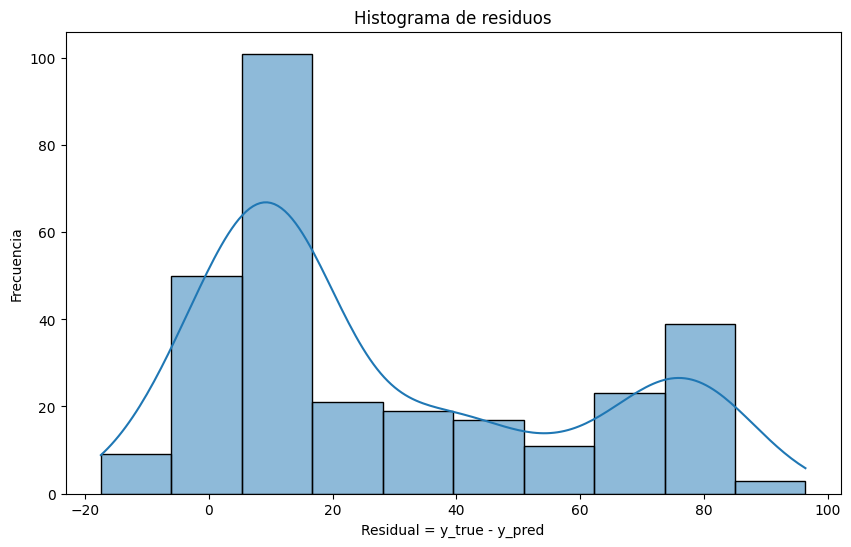

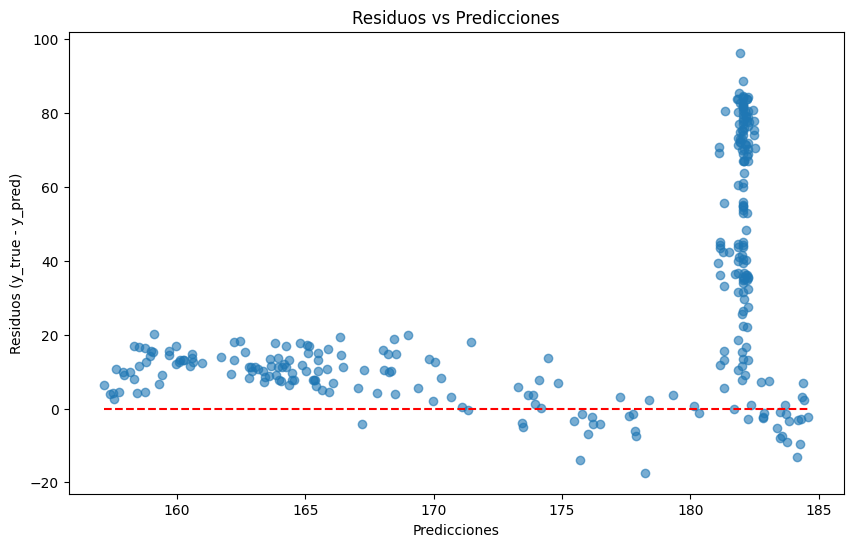

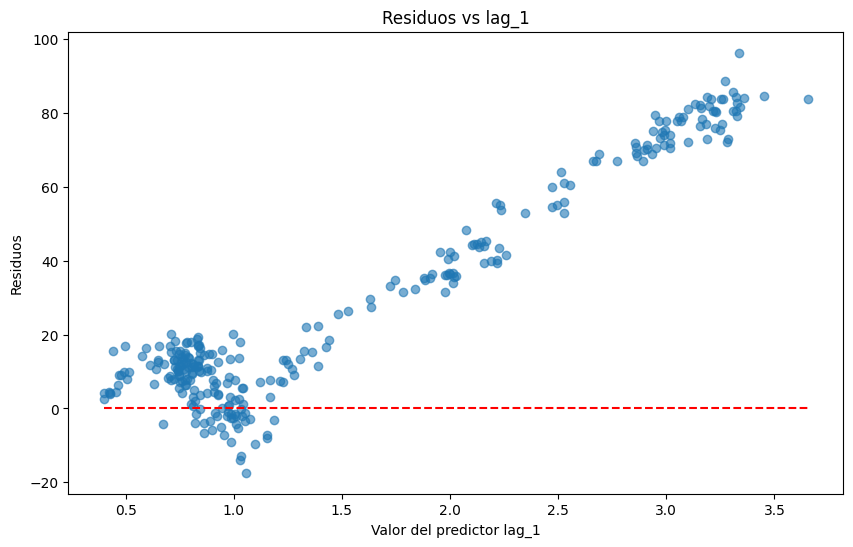

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns


residuals = y_test3 - y_pred3

plt.figure(figsize=(10,6))
sns.histplot(residuals, kde=True)
plt.title("Histograma de residuos")
plt.xlabel("Residual = y_true - y_pred")
plt.ylabel("Frecuencia")
plt.show()

plt.figure(figsize=(10,6))
plt.scatter(y_pred3, residuals, alpha=0.6)
plt.hlines(0, xmin=y_pred3.min(), xmax=y_pred3.max(), colors='r', linestyles='--')
plt.title("Residuos vs Predicciones")
plt.xlabel("Predicciones")
plt.ylabel("Residuos (y_true - y_pred)")
plt.show()

plt.figure(figsize=(10,6))
plt.scatter(X_test3[:, features3.index("lag_1")], residuals, alpha=0.6)
plt.hlines(0, xmin=X_test3[:, features3.index("lag_1")].min(), xmax=X_test3[:, features3.index("lag_1")].max(), colors='r', linestyles='--')
plt.title("Residuos vs lag_1")
plt.xlabel("Valor del predictor lag_1")
plt.ylabel("Residuos")
plt.show()


In [30]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

df12 = df3.copy()

df12["lag_1_sqrt"] = np.sqrt(df12["lag_1"].clip(lower=0))

poly = PolynomialFeatures(degree=2, include_bias=False)
lag1_poly = poly.fit_transform(df12[["lag_1_sqrt"]])
df12["lag_1_poly1"] = lag1_poly[:, 0]
df12["lag_1_poly2"] = lag1_poly[:, 1]

threshold = df12["lag_1_sqrt"].quantile(0.99)
df12 = df12[df12["lag_1_sqrt"] <= threshold].reset_index(drop=True)

features12 = ["Close", "HL_diff", "OC_diff", "MA_5", "MA_10", "Vol_diff", "RSI", "MACD"] \
             + [f"lag_{i}" for i in range(1, 6)] \
             + ["lag_1_sqrt", "lag_1_poly1", "lag_1_poly2"]

X12 = df12[features12]
y12 = df12["Target"]

scaler12 = StandardScaler()
X12_scaled = scaler12.fit_transform(X12)

tscv12 = TimeSeriesSplit(n_splits=5)
rf12   = RandomForestRegressor(random_state=42)

param_grid12 = {
    "n_estimators":      [100, 200],
    "max_depth":         [5, 10],
    "min_samples_leaf":  [2, 4]
}

grid_search12 = GridSearchCV(
    estimator=rf12,
    param_grid=param_grid12,
    cv=tscv12,
    scoring="r2",
    n_jobs=-1,
    verbose=2
)

grid_search12.fit(X12_scaled, y12)

print("Mejores parámetros (Bloque 12):", grid_search12.best_params_)
print("Mejor R² en validación temporal (Bloque 12):", grid_search12.best_score_)

split_point12 = int(0.8 * len(X12_scaled))
X_train12, X_test12 = X12_scaled[:split_point12], X12_scaled[split_point12:]
y_train12, y_test12 = y12.iloc[:split_point12], y12.iloc[split_point12:]

best_rf12 = grid_search12.best_estimator_
best_rf12.fit(X_train12, y_train12)
y_pred12 = best_rf12.predict(X_test12)

mse12 = mean_squared_error(y_test12, y_pred12)
r2_12 = r2_score(y_test12, y_pred12)

print(f"MSE (Bloque 12): {mse12:.4f}")
print(f"R²  (Bloque 12): {r2_12:.4f}")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores parámetros (Bloque 12): {'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 100}
Mejor R² en validación temporal (Bloque 12): 0.5266552968804386
MSE (Bloque 12): 1355.5514
R²  (Bloque 12): -0.2312


Rolling-window MSE: 23.5125
Rolling-window R² : 0.9842


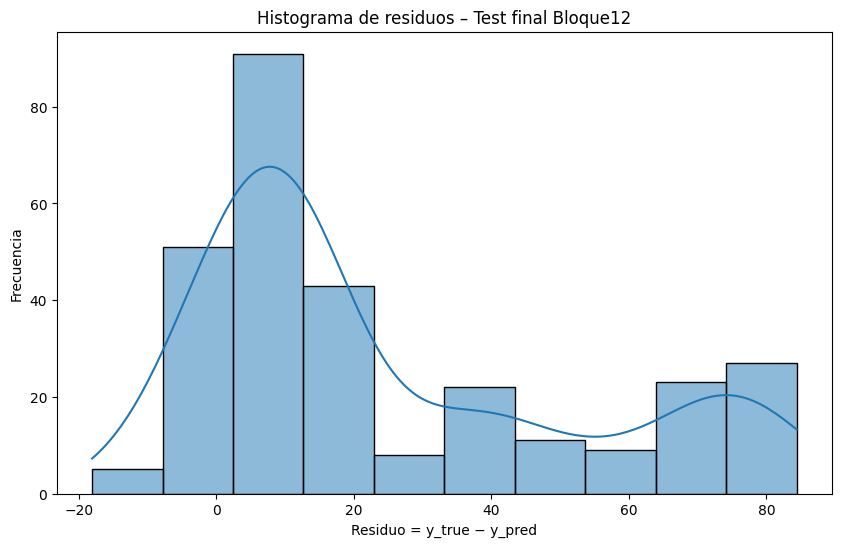

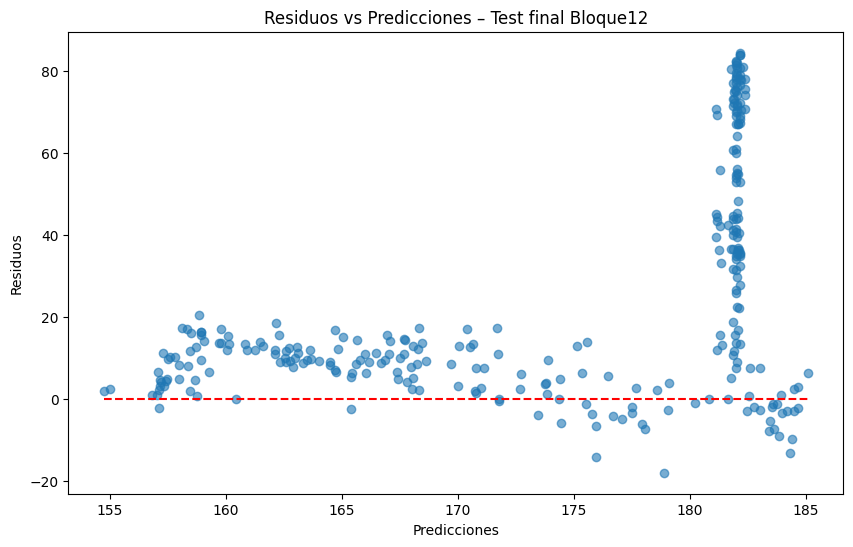

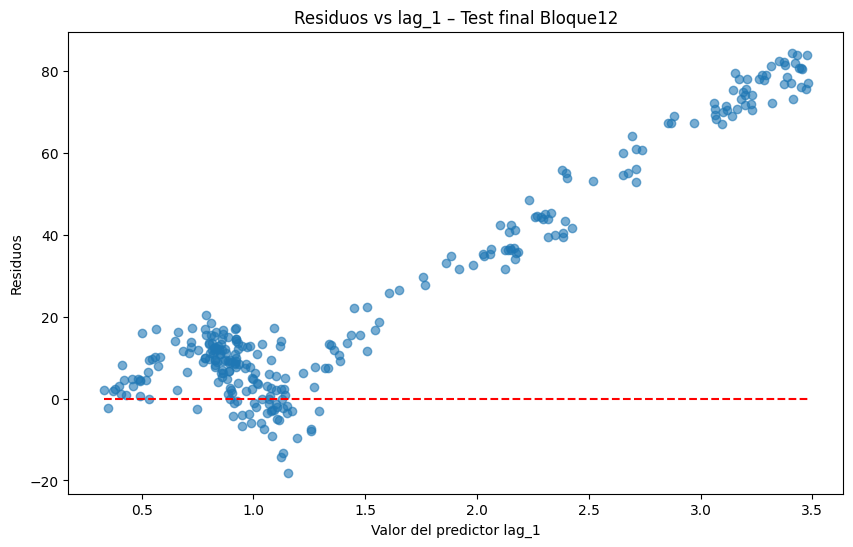

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score


resid = pd.Series(y_test_reg, index=X_test_reg.index) - pd.Series(y_pred_rf, index=X_test_reg.index)

win = min(60, len(resid))
rw_mse = mean_squared_error(resid.shift(1).dropna(), resid.rolling(win).mean().dropna())
rw_r2  = r2_score( pd.Series(y_test_reg).shift(1).dropna()[:len(y_pred_rf)],
                   pd.Series(y_pred_rf).rolling(win).mean().dropna() )
print(f"Rolling-window MSE: {rw_mse:0.4f}")
print(f"Rolling-window R² : {rw_r2:0.4f}")

plt.figure(figsize=(10,6))
sns.histplot(resid, bins=30, kde=True, color="#89a6ff", alpha=0.65, edgecolor="k")
plt.title("Histograma de residuos – Test final Bloque12")
plt.xlabel("Residuo = y_true – y_pred")
plt.ylabel("Frecuencia")
plt.show()

plt.figure(figsize=(10,6))
plt.scatter(y_pred_rf, resid, s=25, alpha=0.8)
plt.axhline(0, color="red", ls="--")
plt.title("Residuos vs Predicciones – Test final Bloque12")
plt.xlabel("Predicciones")
plt.ylabel("Residuos")
plt.show()

# 4) Dispersión: residuos vs. lag_1 (o la feature que quieras inspeccionar)
col_lag1 = [c for c in X_test_reg.columns if c.lower().startswith("lag_1")]
if col_lag1:
    xlag = X_test_reg[col_lag1[0]]
    plt.figure(figsize=(10,6))
    plt.scatter(xlag, resid, s=25, alpha=0.8)
    plt.axhline(0, color="red", ls="--")
    plt.title("Residuos vs lag_1 – Test final Bloque12")
    plt.xlabel("Valor del predictor lag_1")
    plt.ylabel("Residuos")
    plt.show()


In [32]:
!pip -q install yfinance
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report

ticker = "ALICORC1.LM"
data = yf.download(ticker, period="3y", interval="1d")
data = data.dropna()
data.head()


/tmp/ipython-input-1841515804.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, period="3y", interval="1d")  # datos diarios
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM
Date,,,,,
2022-11-08,6.088185,6.106495,6.088185,6.088185,41420
2022-11-09,6.179737,6.234668,6.088185,6.088185,97625
2022-11-10,6.225513,6.225513,6.179737,6.179737,109873
2022-11-11,6.591719,6.591719,6.179737,6.179737,18618111
2022-11-14,6.591719,6.591719,6.408616,6.491013,637734


In [8]:
!pip -q install yfinance ipywidgets
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report
from IPython.display import display


ticker = "ALICORC1.LM"
data = yf.download(ticker, period="3y", interval="1d")
data = data.dropna()
print("Columnas disponibles:", data.columns.tolist())
data.head()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 16.2 MB/s eta 0:00:00


/tmp/ipython-input-1916289559.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, period="3y", interval="1d")
[*********************100%***********************]  1 of 1 completed

Columnas disponibles: [('Close', 'ALICORC1.LM'), ('High', 'ALICORC1.LM'), ('Low', 'ALICORC1.LM'), ('Open', 'ALICORC1.LM'), ('Volume', 'ALICORC1.LM')]


Price,Close,High,Low,Open,Volume
Ticker,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM,ALICORC1.LM
Date,,,,,
2022-11-08,6.088185,6.106495,6.088185,6.088185,41420
2022-11-09,6.179737,6.234668,6.088185,6.088185,97625
2022-11-10,6.225513,6.225513,6.179737,6.179737,109873
2022-11-11,6.591719,6.591719,6.179737,6.179737,18618111
2022-11-14,6.591719,6.591719,6.408616,6.491013,637734


In [12]:
df = data.copy()

df.columns = ['|'.join(col) if isinstance(col, tuple) else col for col in df.columns]

col = [c for c in df.columns if "Close" in c][0]
print("Usando columna:", col)

df["Return"] = df[col].pct_change()
for lag in [1, 2, 3, 5, 7]:
    df[f"Lag_{lag}"] = df[col].shift(lag)
df["MA_5"] = df[col].rolling(window=5).mean()
df["MA_10"] = df[col].rolling(window=10).mean()
df = df.dropna()

df["Target_Reg"] = df[col].shift(-1)
df["Target_Clf"] = (df[col].shift(-1) > df[col]).astype(int)
df = df.dropna()

features = [c for c in df.columns if isinstance(c, str) and (c.startswith("Lag_") or c.startswith("MA_"))]
X = df[features]
y_reg = df["Target_Reg"]
y_clf = df["Target_Clf"]

from sklearn.model_selection import train_test_split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, shuffle=False)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X, y_clf, test_size=0.2, shuffle=False)

print("Features:", features)
print("Regresión train/test:", X_train_reg.shape, X_test_reg.shape)
print("Clasificación train/test:", X_train_clf.shape, X_test_clf.shape)



Usando columna: Close|ALICORC1.LM
Features: ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_5', 'Lag_7', 'MA_5', 'MA_10']
Regresión train/test: (587, 7) (147, 7)
Clasificación train/test: (587, 7) (147, 7)


In [13]:

rf_reg = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf_reg.fit(X_train_reg, y_train_reg)

y_pred_reg = rf_reg.predict(X_test_reg)

mse = mean_squared_error(y_test_reg, y_pred_reg)
print(f"RandomForestRegressor MSE: {mse:.4f}")

importances = rf_reg.feature_importances_
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)
print("Importancia de variables (Regresión):\n", feat_imp)

df_results_reg = pd.DataFrame({
    "Real": y_test_reg,
    "Predicción": y_pred_reg
})
display(df_results_reg.head(10))


RandomForestRegressor MSE: 0.9901
Importancia de variables (Regresión):
 Lag_1    0.403489
MA_5     0.382415
MA_10    0.125434
Lag_2    0.042654
Lag_3    0.028764
Lag_7    0.010830
Lag_5    0.006414
dtype: float64


,Real,Predicción
Date,,
2025-04-04,8.07310,8.163965
2025-04-07,8.07310,8.163965
2025-04-08,8.12087,8.169326
2025-04-09,8.12087,8.167559
2025-04-10,8.07310,8.157024
2025-04-11,8.10000,8.155216
2025-04-14,8.10000,8.156171
2025-04-15,8.08000,8.157024
2025-04-16,8.08000,8.156171


In [14]:
# Modelo B: ExtraTreesRegressor
et_reg = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
et_reg.fit(X_train_reg, y_train_reg)

y_pred_et = et_reg.predict(X_test_reg)

mse_et = mean_squared_error(y_test_reg, y_pred_et)
print(f"ExtraTreesRegressor MSE: {mse_et:.4f}")

importances_et = et_reg.feature_importances_
feat_imp_et = pd.Series(importances_et, index=features).sort_values(ascending=False)
print("Importancia de variables (ExtraTrees):\n", feat_imp_et)

df_results_et = pd.DataFrame({
    "Real": y_test_reg,
    "Predicción_ET": y_pred_et
})
display(df_results_et.head(10))


ExtraTreesRegressor MSE: 1.0182
Importancia de variables (ExtraTrees):
 Lag_1    0.248655
MA_5     0.229344
Lag_2    0.173840
MA_10    0.171406
Lag_3    0.107178
Lag_5    0.057357
Lag_7    0.012221
dtype: float64


,Real,Predicción_ET
Date,,
2025-04-04,8.07310,8.153732
2025-04-07,8.07310,8.157831
2025-04-08,8.12087,8.157831
2025-04-09,8.12087,8.158201
2025-04-10,8.07310,8.157136
2025-04-11,8.10000,8.152177
2025-04-14,8.10000,8.157515
2025-04-15,8.08000,8.158763
2025-04-16,8.08000,8.149263


In [15]:
# Modelo C: RandomForestClassifier
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf_clf.fit(X_train_clf, y_train_clf)
y_pred_clf = rf_clf.predict(X_test_clf)

acc = accuracy_score(y_test_clf, y_pred_clf)
print(f"RandomForestClassifier Accuracy: {acc:.4f}")
print("Classification Report:\n", classification_report(y_test_clf, y_pred_clf))

feat_imp_clf = pd.Series(rf_clf.feature_importances_, index=features).sort_values(ascending=False)
print("Importancia de variables (Clasificación):\n", feat_imp_clf)

df_results_clf = pd.DataFrame({
    "Real (sube=1/baja=0)": y_test_clf,
    "Predicción": y_pred_clf
})
display(df_results_clf.head(10))


RandomForestClassifier Accuracy: 0.6531
Classification Report:
               precision    recall  f1-score   support

           0       0.65      1.00      0.79        96
           1       0.00      0.00      0.00        51

    accuracy                           0.65       147
   macro avg       0.33      0.50      0.40       147
weighted avg       0.43      0.65      0.52       147

Importancia de variables (Clasificación):
 MA_10    0.186413
Lag_7    0.163278
MA_5     0.154925
Lag_1    0.139275
Lag_3    0.127116
Lag_2    0.118019
Lag_5    0.110974
dtype: float64


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Real (sube=1/baja=0),Predicción
Date,,
2025-04-04,0,0
2025-04-07,0,0
2025-04-08,1,0
2025-04-09,0,0
2025-04-10,0,0
2025-04-11,1,0
2025-04-14,0,0
2025-04-15,0,0
2025-04-16,0,0


Distribución antes de entrenamiento:
Target_Clf
0    380
1    207
Name: count, dtype: int64 
 Target_Clf
0    96
1    51
Name: count, dtype: int64
Balanced RF Accuracy: 0.6531
Balanced RF ROC-AUC: 0.5078
Classification Report (balanced):
               precision    recall  f1-score   support

           0       0.65      1.00      0.79        96
           1       0.00      0.00      0.00        51

    accuracy                           0.65       147
   macro avg       0.33      0.50      0.40       147
weighted avg       0.43      0.65      0.52       147

Importancia variables (balanced):
 MA_10    0.179076
Lag_7    0.155609
MA_5     0.150588
Lag_1    0.148243
Lag_3    0.131077
Lag_5    0.126748
Lag_2    0.108660
dtype: float64


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


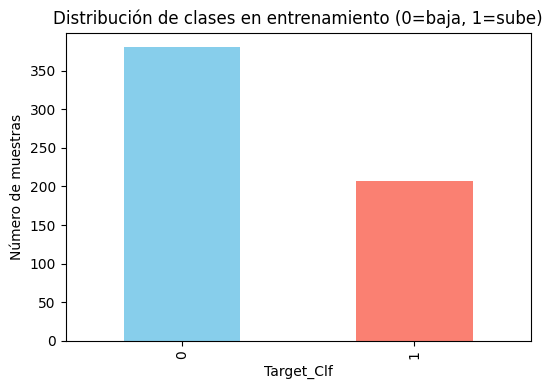

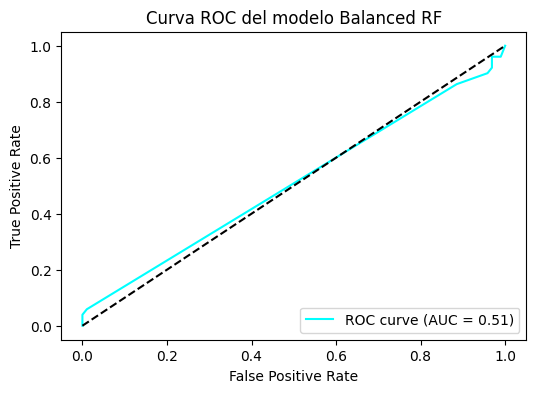

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

print("Distribución antes de entrenamiento:")
print(y_train_clf.value_counts(), "\n", y_test_clf.value_counts())

rf_clf_bal = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)
rf_clf_bal.fit(X_train_clf, y_train_clf)
y_pred_bal = rf_clf_bal.predict(X_test_clf)
y_proba_bal = rf_clf_bal.predict_proba(X_test_clf)[:,1]

acc_bal = accuracy_score(y_test_clf, y_pred_bal)
roc_auc = roc_auc_score(y_test_clf, y_proba_bal)
print(f"Balanced RF Accuracy: {acc_bal:.4f}")
print(f"Balanced RF ROC-AUC: {roc_auc:.4f}")
print("Classification Report (balanced):\n", classification_report(y_test_clf, y_pred_bal))

feat_imp_bal = pd.Series(rf_clf_bal.feature_importances_, index=features).sort_values(ascending=False)
print("Importancia variables (balanced):\n", feat_imp_bal)

plt.figure(figsize=(6,4))
y_train_clf.value_counts().plot(kind='bar', color=['skyblue','salmon'])
plt.title("Distribución de clases en entrenamiento (0=baja, 1=sube)")
plt.ylabel("Número de muestras")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test_clf, y_proba_bal)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.2f})", color='cyan')
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC del modelo Balanced RF")
plt.legend(loc="lower right")
plt.show()


In [17]:
import pandas as pd

X_last = df[features].iloc[[-1]]

last_close = df[col].iloc[-1]

pred_close_rf = float(rf_reg.predict(X_last)[0])
pred_close_et = float(et_reg.predict(X_last)[0])

proba_up = float(rf_clf.predict_proba(X_last)[0, 1])
pred_up = int(proba_up >= 0.5)

out = pd.DataFrame({
    "Último_cierre_real": [last_close],
    "Pred_RF_cierre_siguiente": [pred_close_rf],
    "Pred_ET_cierre_siguiente": [pred_close_et],
    "Δ% RF vs último": [100*(pred_close_rf/last_close - 1)],
    "Δ% ET vs último": [100*(pred_close_et/last_close - 1)],
    "Prob_subir_RF": [proba_up],
    "Pred_subir(>=0.5)": [pred_up]
})
out.round(4)


,Último_cierre_real,Pred_RF_cierre_siguiente,Pred_ET_cierre_siguiente,Δ% RF vs último,Δ% ET vs último,Prob_subir_RF,Pred_subir(>=0.5)
0,9.35,8.1514,8.1349,-12.8189,-12.9954,0.3485,0


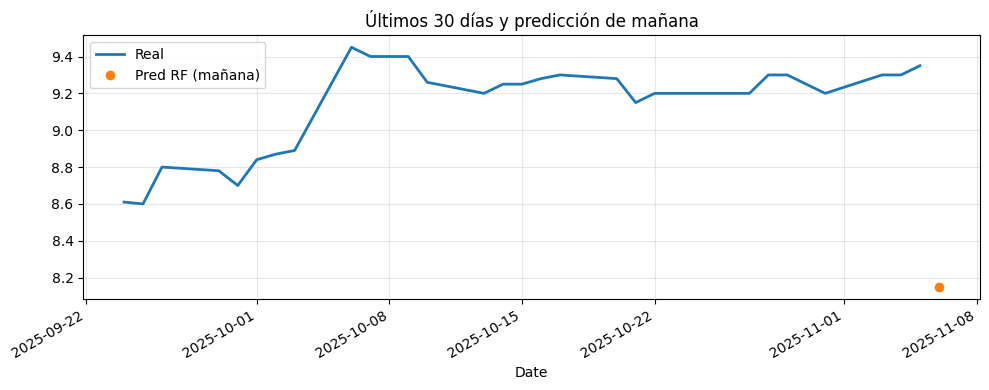

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
df[col].tail(30).plot(label="Real", lw=2)
pd.Series([pred_close_rf], index=[df.index[-1] + pd.Timedelta(days=1)]).plot(
    style="o", label="Pred RF (mañana)"
)
plt.title("Últimos 30 días y predicción de mañana")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()


In [19]:
!pip -q install yfinance plotly

import warnings, numpy as np, pandas as pd, yfinance as yf
from datetime import timedelta
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import plotly.graph_objects as go
import ipywidgets as w
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
np.random.seed(42)


In [20]:
def load_prices(ticker:str, interval="60m", period="60d"):
    """
    Intenta intradía; si no hay datos por hora, cae a diario automáticamente.
    Devuelve df con columna Close y un flag intraday=True/False.
    """
    df = yf.download(ticker, interval=interval, period=period, auto_adjust=True, progress=False)
    if df is None or df.empty:
        df = yf.download(ticker, interval="1d", period="3y", auto_adjust=True, progress=False)
        return df[['Close']].dropna().copy(), False
    return df[['Close']].dropna().copy(), True

ticker_default = "ALICORC1.LM"
df_raw, is_intraday = load_prices(ticker_default)
print(f"Ticker: {ticker_default} | Intradía disponible: {is_intraday} | filas: {len(df_raw)}")
df_raw.tail()


Ticker: ALICORC1.LM | Intradía disponible: True | filas: 58


Price,Close
Ticker,ALICORC1.LM
Datetime,
2025-10-31 13:30:00+00:00,9.20
2025-11-03 14:30:00+00:00,9.30
2025-11-04 14:30:00+00:00,9.30
2025-11-05 14:30:00+00:00,9.35
2025-11-06 14:30:00+00:00,9.32


In [21]:
def build_features(df:pd.DataFrame, lags=(1,2,3,5,7), ma=(5,10)):
    df = df.copy()
    for L in lags:
        df[f"Lag_{L}"] = df['Close'].shift(L)
    for m in ma:
        df[f"MA_{m}"] = df['Close'].rolling(m).mean()
    df = df.dropna().copy()
    X = df[[c for c in df.columns if c.startswith("Lag_") or c.startswith("MA_")]]
    y = df['Close']
    return df, X, y

def time_split_indices(n:int, test_size_ratio=0.2):
    test = int(np.ceil(n*test_size_ratio))
    idx_train = np.arange(0, n-test)
    idx_test  = np.arange(n-test, n)
    return idx_train, idx_test


In [22]:
def fit_rf(X, y, n_estimators=400, max_depth=None, random_state=42):
    rf = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=random_state, n_jobs=-1)
    rf.fit(X, y)
    return rf

def recursive_forecast(df_feat, X, model, horizon, lags=(1,2,3,5,7), ma=(5,10)):
    """
    Predicción recursiva: usa la última fila como punto de partida y va
    agregando nuevas 'Close' predichas para recomputar lags y MAs.
    """
    work = df_feat.copy()
    preds = []
    for h in range(horizon):
        tmp = work[['Close']].copy()
        for L in lags:
            tmp[f"Lag_{L}"] = tmp['Close'].shift(L)
        for m in ma:
            tmp[f"MA_{m}"] = tmp['Close'].rolling(m).mean()
        row = tmp.dropna().iloc[-1][[c for c in tmp.columns if c.startswith("Lag_") or c.startswith("MA_")]]
        y_hat = model.predict([row.values])[0]
        preds.append(y_hat)
        work = pd.concat([work, pd.DataFrame({"Close":[y_hat]}, index=[work.index[-1] + (work.index.freq or (work.index[-1]-work.index[-2]))])])
    return preds


In [26]:
!pip -q install ipywidgets==8.1.2 plotly==5.24.1
from google.colab import output
output.enable_custom_widget_manager()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.4/139.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 32.2 MB/s eta 0:00:00


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

from ipywidgets import VBox, HBox, Dropdown, IntSlider, FloatLogSlider, IntSlider, DatePicker, HTML
from IPython.display import display, clear_output
import plotly.graph_objects as go

NEON = {
    "bg":        "#0b0f19",
    "grid":      "#1f2a44",
    "font":      "#e6f1ff",
    "line_real": "#00b3ff",
    "dot_pred":  "#ff5af1",
    "accent":    "#00e5ff",
}


In [28]:
w_ticker = Dropdown(
    options=["ALICORC1.LM"], value="ALICORC1.LM", description="Ticker:"
)

w_lags = IntSlider(value=3, min=1, max=7, step=1, description="Lag 1..k")

w_ma5  = IntSlider(value=5, min=3, max=20, step=1, description="MA_5")
w_ma10 = IntSlider(value=10, min=5, max=40, step=1, description="MA_10")

w_estim = FloatLogSlider(value=200, base=10, min=1, max=3, step=0.01, description="n_estim")

w_depth = IntSlider(value=8, min=0, max=30, step=1, description="max_depth")

w_date = DatePicker(description="Fecha obj.")


In [29]:
def build_features(df, k_lag=3, ma5=5, ma10=10):
    df = df.copy()
    col = "Close"
    df["Return"] = df[col].pct_change()

    for lag in range(1, k_lag+1):
        df[f"Lag_{lag}"] = df[col].shift(lag)

    df["MA_5"]  = df[col].rolling(window=ma5).mean()
    df["MA_10"] = df[col].rolling(window=ma10).mean()

    df["Target_Reg"] = df[col].shift(-1)
    df["Target_Clf"] = ((df[col].shift(-1) > df[col])).astype(int)

    df = df.dropna()
    feats = [c for c in df.columns if c.startswith(("Lag_","MA_"))]
    X = df[feats]
    y = df["Target_Reg"]
    return df, X, y


In [31]:
import numpy as np
import pandas as pd
import yfinance as yf

NEON = {
    "bg":   "#0b0f19",
    "grid": "#00e5ff",
    "font": "#e6f3ff",
    "line": "#39ff14",
    "acc":  "#ff5df5"
}

def flatten_cols(df: pd.DataFrame) -> pd.DataFrame:
    """Convierte columnas MultiIndex de yfinance a strings 'Campo|Ticker'."""
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = ["|".join([str(x) for x in col if str(x) != ""]) for col in df.columns]
    else:
        df.columns = [str(c) for c in df.columns]
    return df

def make_base_df(ticker: str, period="3y", interval="1d") -> pd.DataFrame:
    """Descarga datos, aplana columnas y devuelve un DF con una sola col 'Close'."""
    data = yf.download(ticker, period=period, interval=interval, auto_adjust=True).dropna()
    data = flatten_cols(data)

    campos = [c.split("|")[0] for c in data.columns]
    if "Adj Close" in campos:
        base = [c for c in data.columns if c.startswith("Adj Close")]
    elif "Close" in campos:
        base = [c for c in data.columns if c.startswith("Close")]
    else:
        raise ValueError(f"No encuentro 'Adj Close' ni 'Close' en: {sorted(set(campos))}")

    col_flat = base[0]
    df = pd.DataFrame({"Close": data[col_flat]}).dropna()
    return df

ticker_default = "ALICORC1.LM"
df = make_base_df(ticker_default)

def build_features(df: pd.DataFrame, lags=(1,3,5,7), ma5=5, ma10=10):
    df = df.copy()
    for lag in lags:
        df[f"Lag_{lag}"] = df["Close"].shift(lag)
    df["MA_5"]  = df["Close"].rolling(ma5).mean()
    df["MA_10"] = df["Close"].rolling(ma10).mean()
    df = df.dropna()

    feats = [c for c in df.columns if c.startswith("Lag_") or c.startswith("MA_")]
    X = df[feats].copy()
    y = df["Close"].copy()
    return df, X, y


[*********************100%***********************]  1 of 1 completed


In [32]:
import pandas as pd
import plotly.graph_objects as go
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from ipywidgets import VBox, HBox, IntSlider, Dropdown, DatePicker, HTML
from IPython.display import display

try:
    NEON
except NameError:
    NEON = {
        "bg":   "#0b1020",
        "font": "#cfe8ff",
        "grid": "#23324d",
        "line": "#66d9ff",
        "acc":  "#ff6bd6"
    }

try:
    w_ticker, w_lags, w_ma5, w_ma10, w_estim, w_depth, w_date
except NameError:
    w_ticker = Dropdown(
        options=[globals().get("ticker_default", "ALICORC1.LM")],
        value=globals().get("ticker_default", "ALICORC1.LM"),
        description="Ticker:"
    )
    w_lags  = IntSlider(value=3, min=1, max=7, step=1, description="Lag 1..k", continuous_update=False)
    w_ma5   = IntSlider(value=5, min=3, max=10, step=1, description="MA_5",   continuous_update=False)
    w_ma10  = IntSlider(value=10, min=5, max=20, step=1, description="MA_10", continuous_update=False)
    w_estim = IntSlider(value=300, min=50, max=1000, step=50, description="n_estim", continuous_update=False)
    w_depth = IntSlider(value=8, min=0, max=30, step=1, description="max_depth", continuous_update=False)
    w_date  = DatePicker(description="Fecha obj.")

def lags_from_k(k:int):
    base = [1, 2, 3, 5, 7]
    return tuple([x for x in base if x <= k]) or (1,)

out = HTML()

def run_pipeline(*_):
    try:
        lags = lags_from_k(int(w_lags.value))
        df_loc, X, y = build_features(df, lags=lags, ma5=int(w_ma5.value), ma10=int(w_ma10.value))

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

        rf = RandomForestRegressor(
            n_estimators=int(w_estim.value),
            max_depth=(None if int(w_depth.value) == 0 else int(w_depth.value)),
            random_state=42,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)

        pred_next = float(rf.predict(X.iloc[[-1]])[0])

        col = "Close"
        real_series = df_loc[col].tail(30)
        next_day = real_series.index[-1] + pd.Timedelta(days=1)

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=real_series.index, y=real_series.values,
            mode="lines+markers", name="Real",
            line=dict(color=NEON["line"], width=2),
            marker=dict(size=6)
        ))
        fig.add_trace(go.Scatter(
            x=[next_day], y=[pred_next],
            mode="markers", name="Pred RF (mañana)",
            marker=dict(size=12, color=NEON["acc"], line=dict(width=2, color="#ffffff"))
        ))

        fig.update_layout(
            title="Últimos 30 días y predicción (tema neón)",
            paper_bgcolor=NEON["bg"], plot_bgcolor=NEON["bg"],
            font=dict(color=NEON["font"]),
            xaxis=dict(gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
            yaxis=dict(gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
            legend=dict(bgcolor="rgba(0,0,0,0)")
        )

        out.value = fig.to_html(include_plotlyjs="cdn", full_html=False)

    except Exception as e:
        out.value = f"<span style='color:#ff8a8a'><b>Error:</b> {e}</span>"

run_pipeline()
for w in (w_ticker, w_lags, w_ma5, w_ma10, w_estim, w_depth, w_date):
    w.observe(run_pipeline, names="value")

display(
    VBox([
        HBox([w_ticker, w_lags, w_ma5, w_ma10]),
        HBox([w_estim, w_depth, w_date]),
        out
    ])
)


In [37]:
import pandas as pd, numpy as np, plotly.graph_objects as go
from datetime import timedelta
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import yfinance as yf

NEON = {"bg":"#0b1020","font":"#cfe8ff","grid":"#23324d","real":"#66d9ff","pred":"#ff6bd6"}

ticker   = "AAPL"
period   = "30d"
interval = "60m"
lags     = (1,2,3,5,7)
ma_fast, ma_slow = 3, 7
n_estim, max_depth = 400, None
test_size = 0.2

raw = yf.download(ticker, period=period, interval=interval, auto_adjust=True, progress=False)
if raw.empty:
    raise ValueError("Yahoo no devolvió intradía. Cambia ticker/interval/period.")
df = raw.copy()
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ['|'.join(c) for c in df.columns]
cands = [c for c in df.columns if 'Adj Close' in c] or [c for c in df.columns if 'Close' in c]
if not cands:
    raise ValueError("No hay columnas Close/Adj Close.")
close_col = cands[0]
df = pd.DataFrame({"Close": df[close_col]}).dropna()

last_cal_date = df.index[-1].date()
hours_template = df.index[df.index.date==last_cal_date].to_series().dt.time.unique().tolist()
if len(hours_template) < 2:
    raise ValueError("Muy pocas barras intradía (este ticker/interval no trae horas suficientes).")


data = df.copy()
for L in lags:
    data[f"Lag_{L}"] = data["Close"].shift(L)
data[f"MA_{ma_fast}"] = data["Close"].rolling(ma_fast).mean()
data[f"MA_{ma_slow}"] = data["Close"].rolling(ma_slow).mean()
data = data.dropna()
X = data[[c for c in data.columns if c.startswith("Lag_") or c.startswith("MA_")]]
y = data["Close"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, shuffle=False)
rf = RandomForestRegressor(n_estimators=n_estim, max_depth=max_depth, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

window = data.copy()
last_ts = df.index[-1]
target_day = (last_ts + timedelta(days=1)).date()

tz = getattr(last_ts, "tz", None)
future_idx = []
for t in hours_template:
    ts = pd.Timestamp.combine(target_day, t)
    if tz is not None:
        ts = pd.Timestamp(ts).tz_localize(tz)
    future_idx.append(ts)


pred_series = []
for ts in future_idx:
    feat = {f"Lag_{L}": window["Close"].iloc[-L] for L in lags}
    feat[f"MA_{ma_fast}"] = window["Close"].iloc[-ma_fast:].mean()
    feat[f"MA_{ma_slow}"] = window["Close"].iloc[-ma_slow:].mean()
    x_new = pd.DataFrame([feat], index=[ts])
    y_hat = float(rf.predict(x_new)[0])
    pred_series.append((ts, y_hat))
    window = pd.concat([window[["Close"]], pd.DataFrame({"Close":[y_hat]}, index=[ts])])

pred_intraday = pd.Series(dict(pred_series), name="Pred_Close")

fig = go.Figure()
last_day_real = df.loc[df.index.date==last_cal_date, "Close"]
fig.add_trace(go.Scatter(x=last_day_real.index, y=last_day_real.values,
                         mode="lines+markers", name=f"Real {last_cal_date}",
                         line=dict(color=NEON["real"], width=2), marker=dict(size=5)))
fig.add_trace(go.Scatter(x=pred_intraday.index, y=pred_intraday.values,
                         mode="lines+markers", name=f"Pred {target_day}",
                         line=dict(color=NEON["pred"], width=3), marker=dict(size=7)))
fig.update_layout(title=f"{ticker} — Predicción intradía del próximo día ({interval})",
                  paper_bgcolor=NEON["bg"], plot_bgcolor=NEON["bg"],
                  font=dict(color=NEON["font"]),
                  xaxis=dict(gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
                  yaxis=dict(gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
                  legend=dict(bgcolor="rgba(0,0,0,0)"))
fig.show()


In [39]:
!pip -q install yfinance==0.2.43 plotly==5.24.1 ipywidgets==8.1.2

import warnings, numpy as np, pandas as pd, yfinance as yf
from datetime import datetime, time, timedelta
from sklearn.ensemble import RandomForestRegressor
from ipywidgets import VBox, HBox, Dropdown, IntSlider, DatePicker, Button, Output, HTML
import plotly.graph_objects as go

warnings.filterwarnings("ignore")

NEON = {
    "bg": "#0b1020",
    "grid": "rgba(0,229,255,0.33)",
    "font": "#d8f6ff",
    "line_real": "#58ffa1",
    "line_pred": "#ff58f0",
    "dot_pred": "#ff58f0"
}

def apply_neon(fig, title):
    fig.update_layout(
        title=title,
        paper_bgcolor=NEON["bg"], plot_bgcolor=NEON["bg"],
        font=dict(color=NEON["font"]),
        xaxis=dict(showgrid=True, gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
        yaxis=dict(showgrid=True, gridcolor=NEON["grid"], zerolinecolor=NEON["grid"]),
        legend=dict(bgcolor="rgba(0,0,0,0)")
    )


w_ticker = Dropdown(
    options=["AAPL", "MSFT", "NVDA", "SPY", "ALICORC1.LM"],
    value="AAPL",
    description="Ticker:",
    layout={"width":"260px"}
)
w_step = Dropdown(
    options=[("60 min","60m"), ("30 min","30m"), ("15 min","15m"), ("5 min","5m")],
    value="60m",
    description="Paso:",
    layout={"width":"160px"}
)
w_estim = IntSlider(value=300, min=100, max=1000, step=50, description="n_estim")
w_depth = IntSlider(value=8, min=0, max=20, step=1, description="max_depth")
w_date = DatePicker(description="Fecha:", disabled=False)
btn = Button(description="Analizar", button_style="info", icon="play")
out = Output()

msg = HTML()

def fetch_intraday(ticker, period="60d", interval="60m"):
    df = yf.download(
        ticker, period=period, interval=interval, auto_adjust=True, progress=False
    )
    if isinstance(df.columns, pd.MultiIndex):
        cols = [c.split("|")[0] if "|" in c else c for c in df.columns.get_level_values(0).astype(str)]
        df.columns = cols
    if "Close" not in df.columns:
        if "Adj Close" in df.columns:
            df["Close"] = df["Adj Close"]
        else:
            close_candidates = [c for c in df.columns if c.lower().startswith("close")]
            if close_candidates:
                df["Close"] = df[close_candidates[0]]
    df = df.dropna().copy()
    return df

def hour_grid_for_day(day: datetime.date, step: str, tzinfo=None):
    minutes = dict(m="minutes", h="hours")
    gran = int(step[:-1])
    t0 = datetime.combine(day, time(0,0))
    idx = []
    cur = t0
    while cur.date() == day:
        ts = pd.Timestamp(cur)
        if tzinfo is not None and ts.tz is None:
            ts = ts.tz_localize(tzinfo)
        idx.append(ts)
        cur += timedelta(minutes=gran)
    return idx

def build_features(df, lags=(1,2,3,5,7), ma5=5, ma10=10):
    d = df.copy()
    for lag in lags:
        d[f"Lag_{lag}"] = d["Close"].shift(lag)
    d["MA_5"] = d["Close"].rolling(ma5).mean()
    d["MA_10"] = d["Close"].rolling(ma10).mean()
    d = d.dropna().copy()
    X = d[[c for c in d.columns if c.startswith("Lag_") or c.startswith("MA_")]].copy()
    y = d["Close"].copy()
    return d, X, y

def iterative_predict_next_day(train_d, X, y, hours_template, n_estim=300, max_depth=8):
    rf = RandomForestRegressor(
        n_estimators=int(n_estim), max_depth=(None if max_depth==0 else int(max_depth)),
        random_state=42, n_jobs=-1
    )
    rf.fit(X, y)

    d = train_d.copy()
    preds = []
    for ts in hours_template:
        row = {
            "Lag_1": d["Close"].iloc[-1],
            "Lag_2": d["Close"].iloc[-2] if len(d)>=2 else d["Close"].iloc[-1],
            "Lag_3": d["Close"].iloc[-3] if len(d)>=3 else d["Close"].iloc[-1],
            "Lag_5": d["Close"].iloc[-5] if len(d)>=5 else d["Close"].iloc[-1],
            "Lag_7": d["Close"].iloc[-7] if len(d)>=7 else d["Close"].iloc[-1],
            "MA_5": d["Close"].iloc[-5:].mean(),
            "MA_10": d["Close"].iloc[-10:].mean()
        }
        X_new = pd.DataFrame([row])
        y_hat = float(rf.predict(X_new)[0])
        preds.append((ts, y_hat))
        d = pd.concat([d, pd.DataFrame({"Close":[y_hat]}, index=[ts])])
    pred_series = pd.Series({ts: val for ts, val in preds}).sort_index()
    return pred_series

def on_click_run(_):
    out.clear_output()
    msg.value = ""
    ticker = w_ticker.value
    step = w_step.value
    the_date = w_date.value

    if the_date is None:
        msg.value = "<b style='color:#ff8a8a'>Selecciona una fecha en el calendario.</b>"
        return

    with out:
        try:

            period = "30d" if step in ("15m","5m") else "60d"
            df = fetch_intraday(ticker, period=period, interval=step)

            if df.empty or "Close" not in df.columns:
                print("No hay datos intradía disponibles para este ticker/intervalo en Yahoo Finance.")
                return

            if len(df) < 200:
                print("Datos intradía insuficientes (se requieren > 200 barras) para un entrenamiento razonable.")
                return

            d, X, y = build_features(df)


            last_ts = d.index[-1]
            tz = getattr(last_ts, "tz", None)
            hours_template = hour_grid_for_day(the_date, step, tzinfo=tz)
            if len(hours_template) < 2:
                print("Con este paso no hay suficientes puntos dentro del día.")
                return

            pred_next_day = iterative_predict_next_day(d, X, y, hours_template,
                                                       n_estim=w_estim.value, max_depth=w_depth.value)

            last_day = d.index[-1].date()
            real_last_day = d.loc[str(last_day), "Close"] if str(last_day) in d.index.strftime("%Y-%m-%d") else d["Close"].tail(min(1,len(d)))

            fig = go.Figure()
            try:
                if isinstance(real_last_day, pd.Series) and len(real_last_day) > 1:
                    fig.add_trace(go.Scatter(
                        x=real_last_day.index, y=real_last_day.values,
                        mode="lines+markers", name=f"Real {last_day}",
                        line=dict(color=NEON["line_real"], width=2),
                        marker=dict(size=5)
                    ))
            except Exception:
                pass

            fig.add_trace(go.Scatter(
                x=pred_next_day.index, y=pred_next_day.values,
                mode="lines+markers", name=f"Pred {the_date}",
                line=dict(color=NEON["line_pred"], width=2),
                marker=dict(size=6, color=NEON["dot_pred"])
            ))

            apply_neon(fig, f"{ticker} — Predicción intradía del día seleccionado ({step})")
            fig.show()

        except Exception as e:
            print(f"Error: {e}")

btn.on_click(on_click_run)

display(
    VBox([
        HBox([w_ticker, w_step, w_estim, w_depth, w_date, btn]),
        msg,
        out
    ])
)
